# Persistence 실습: 멈춘 대출 처리를 이어 가고 기록은 한 번만 남기기

**이 노트북에서 할 일**

1. 대출 신청 한 건을 처리하는 그래프에 SQLite 체크포인터와 멱등 키 확인을 붙입니다.
2. 대출 기록을 적은 노드를 실패 흉내로 멈추고, 새 연결로 파일을 다시 열어 이어 갑니다.
3. 쓰기 방식 하나만 바꿔 다시 실행하고, 대출 기록 파일의 줄 수로 두 실행을 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
01절처럼 매번 같은 값을 내는 우리 노드로, 저장된 값이 맞는지 출력으로 가릅니다.

실패는 모두 이 절에서 일부러 만든 실패 흉내입니다.
대출 기록은 실제 서비스가 아니라, 기록 파일에 대출 키를 한 줄 적는 것으로 대신합니다.
자식 프로세스는 띄우지 않고, 모든 일을 이 커널 안에서 합니다.

노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
SQLite 파일과 대출 기록 파일은 이 임시 폴더에 생기고, 실습 폴더에는 파일을 남기지 않습니다.
읽어 오는 자료 파일은 없습니다.

걸린 시간은 재지 않습니다.
교재 출력을 만든 실행에서는 노트북 전체가 5초 안에 끝났습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11입니다.
SQLite 체크포인터는 langgraph-checkpoint-sqlite 3.0.3에 들어 있습니다.

교재 출력은 Linux의 Python 3.12.13과, 그 Python에 들어 있는 SQLite 3.53.1로 만들었습니다.
Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~06절에서 쓴 이름과 Ch 2에서 배운 문법만 씁니다.

실습 폴더 `labs/part6/ch23-persistence`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림입니다. 맨 위에 초록 상자 쓰기 방식 write_plan 실행 1 idempotent 실행 2 naive, 파란 상자 05절 실패 흉내 failure_plan TimeoutError, 파란 상자 06절 append_key_once 도구 파일이 나란히 있고, 세 상자에서 화살표가 파란 상자 노드 record_loan 대출 키를 적은 뒤 알림에서 멈출 수 있음으로 모입니다. 노드 record_loan 오른쪽에는 초록 상자 대출 신청 한 건 스레드 M-0317 대출 키 loan-2307과 회색 상자 03절 SqliteSaver SQLite 파일이 있습니다. 노드 record_loan, invoke 화살표가 붙은 대출 신청, SqliteSaver에서 화살표 셋이 맨 아래 회색 상자 SQLite 체크포인터를 붙인 그래프 노드 receive_request 노드 record_loan으로 모이는 그림](attachment:07-1-세-절-기능을-붙인-대출-처리-그래프.png)

위에서 아래로 읽습니다.
파란 상자는 우리가 적은 코드이고, 회색 상자는 라이브러리가 준 체크포인터와 그것을 붙인 그래프입니다.
05절 실패 흉내와 06절 함수는 노드 `record_loan` 안에서 씁니다.
노드와 대출 신청과 체크포인터에서 온 화살표 셋이 맨 아래 그래프로 모입니다.
초록 상자 둘 가운데 쓰기 방식이 실행 2에서 바꾸는 값이고, 대출 신청은 두 실행에 같게 넣습니다.
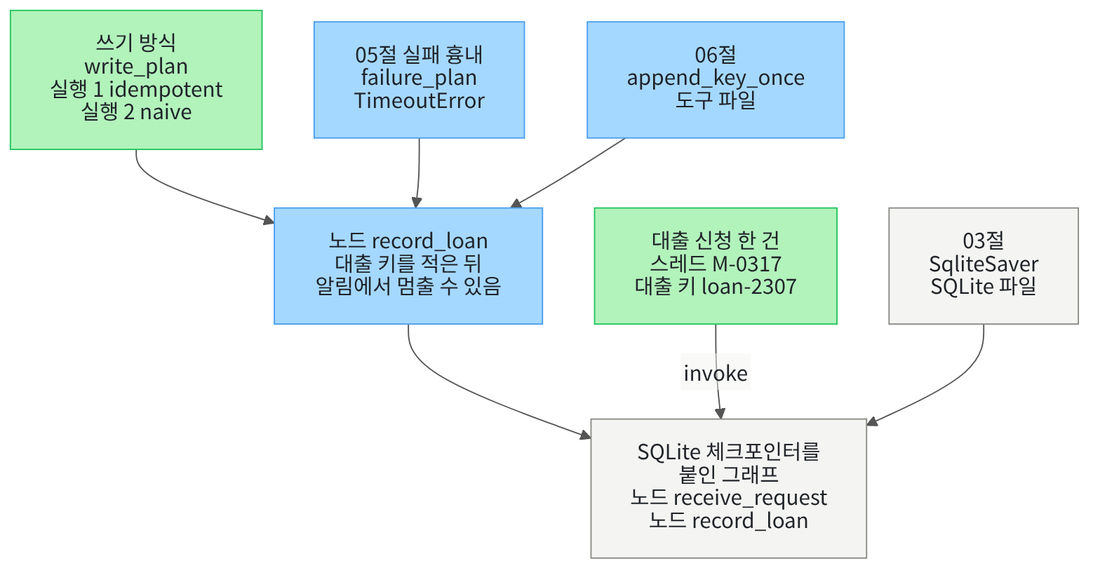

## 1. 준비

이번 절은 이 챕터의 실습입니다.
03절 SQLite 체크포인터, 05절 실패 흉내와 이어 가기, 06절 멱등 키 확인을 대출 처리 한 건에 모읍니다.
첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint-sqlite==3.0.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint-sqlite:", version("langgraph-checkpoint-sqlite"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint-sqlite: 3.0.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint-sqlite: 3.0.3`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01·02절, `sqlite3`와 `SqliteSaver`는 03절과 같습니다.
마지막 줄은 04절과 06절에서 배운 함수 다섯을 도구 파일 `checkpoint_tools.py`에서 가져옵니다.
이 절에서 새로 가져오는 이름은 없습니다.

In [2]:
# 그래프 이름(Ch 13 01·02절)과 SQLite 체크포인터(03절)를 가져오고, 04·06절에서 배운 함수 다섯을 도구 파일에서 가져옵니다
import operator
import sqlite3
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver
from checkpoint_tools import append_key, append_key_once, new_prefix, read_record, read_saved

print("도구 파일에서 가져온 함수:", "append_key, append_key_once, new_prefix, read_record, read_saved")

도구 파일에서 가져온 함수: append_key, append_key_once, new_prefix, read_record, read_saved


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: append_key, append_key_once, new_prefix, read_record, read_saved`가 보입니다.
함수 `read_saved`·`read_record`·`new_prefix`는 04절 노트북 3절에서 처음 적은 함수입니다.
함수 `append_key`와 `append_key_once`는 06절 노트북 2절에서 처음 적은 함수입니다.
이 절에서 도구 파일에 더한 함수는 없습니다.

앞에서 배운 함수는 `checkpoint_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
그래서 임시 폴더로 작업 위치를 옮기기 전에 가져왔습니다.

교재 출력은 프로젝트 맨 위에서 커널을 띄운 실행입니다.
실행 도구가 도구 파일 폴더를 따로 알려 주어, 그 자리에서도 가져오기가 되었습니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절의 SQLite 파일과 대출 기록 파일은 모두 이 임시 폴더에 생깁니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 4 03절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch23-07-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch23-07-이 들어 있는가:", "ch23-07-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch23-07-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch23-07-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 오늘 처리할 대출 한 건

이번 실습은 자료실 창구에 들어온 대출 신청 한 건을 처리합니다.
처리는 노드 둘로 나눕니다.
첫째 노드는 신청을 받고, 둘째 노드는 대출 기록 파일에 대출 키를 적은 뒤 이용자에게 알림을 보냅니다.
알림은 실제로 보내지 않고, 보내다가 시간이 초과되는 실패 흉내만 냅니다.

다음 셀은 오늘 쓸 두 값을 정하고 출처와 함께 출력합니다.
두 값 모두 실행 전에 정했습니다.

In [4]:
# 오늘 처리할 대출 신청 한 건의 값 둘을 정합니다(실행 전에 정한 값)
member_id = "M-0317"
loan_key = "loan-2307"
print("이용자 번호:", member_id)
print("이용자 번호 출처: Ch 21 03절 실행 정보의 이용자 번호 그대로")
print("대출 키:", loan_key)
print("대출 키 출처: 이 절에서 실행 전에 정한 값(06절 주문 키 order-2306과 같은 모양)")

이용자 번호: M-0317
이용자 번호 출처: Ch 21 03절 실행 정보의 이용자 번호 그대로
대출 키: loan-2307
대출 키 출처: 이 절에서 실행 전에 정한 값(06절 주문 키 order-2306과 같은 모양)


**결과 읽기** — 출력 줄 `이용자 번호: M-0317`과 `대출 키: loan-2307`로 오늘 쓸 값을 확인합니다.
이용자 번호는 스레드 이름으로 씁니다.
01절에서 본 대로, 스레드 이름은 설정 딕셔너리의 `thread_id`에 적습니다.

대출 키는 06절의 주문 키처럼 멱등 키로 씁니다.
같은 대출이면 다시 실행해도 늘 같은 값이어야 합니다.
두 실행 모두 같은 이용자 번호와 같은 대출 키를 씁니다.

## 3. 재료 · 딕셔너리 셋과 상태 형식, 노드 둘

다음 셀은 05절처럼 노드마다 부른 횟수를 셀 딕셔너리와, 실패 흉내를 정할 딕셔너리를 만듭니다.
05절의 `failure_plan`에서 기다릴 초는 뺐습니다.
이번 그래프에는 같은 단계에서 함께 실행되는 노드가 없기 때문입니다.
셋째 딕셔너리 `write_plan`은 대출 기록을 적는 쓰기 방식과, 파일 이름의 앞머리를 정합니다.

앞머리는 04절 함수 `new_prefix`로, 쓰기 방식 이름 뒤에 번호를 붙여 고릅니다.
이 셀을 다시 실행하면 번호가 올라, 앞 실행의 파일과 섞이지 않는 새 파일을 씁니다.
그래서 실행 1을 처음부터 다시 보려면 이 셀부터, 실행 2는 6절 첫 셀부터 차례로 다시 실행합니다.

In [5]:
# 노드마다 부른 횟수, 실패 흉내, 쓰기 방식과 파일 앞머리를 정할 딕셔너리 셋을 만듭니다(05절 모양)
call_count = {"receive_request": 0, "record_loan": 0}
failure_plan = {"fail": True}
# 실행 1의 쓰기 방식은 이미 적힌 키를 건너뛰는 idempotent입니다
write_plan = {"mode": "idempotent"}
# 파일 앞머리는 쓰기 방식 이름에 번호를 붙여 고릅니다(04절 함수 — 이 셀을 다시 실행하면 새 번호)
write_plan["prefix"] = new_prefix(write_plan["mode"])
print("부른 횟수:", call_count)
print("실패 흉내:", failure_plan)
print("쓰기 방식:", write_plan)

부른 횟수: {'receive_request': 0, 'record_loan': 0}
실패 흉내: {'fail': True}
쓰기 방식: {'mode': 'idempotent', 'prefix': 'idempotent-1'}


**결과 읽기** — 출력 줄 `부른 횟수: {'receive_request': 0, 'record_loan': 0}`과 `실패 흉내: {'fail': True}`입니다.
출력 줄 `쓰기 방식: {'mode': 'idempotent', 'prefix': 'idempotent-1'}`가 실행 1의 설정입니다.
실행 2에서는 쓰기 방식 하나만 바꾸고, 앞머리는 그 이름을 따라 새로 고릅니다.
값 `idempotent`는 06절 `append_key_once`로, 값 `naive`는 `append_key`로 적는다는 뜻입니다.
세 딕셔너리는 체크포인트 밖에 있고, 노드가 노트북에서 만든 이름 그대로 읽고 고칩니다.

다음 셀은 상태 형식입니다.
칸 `loan_key`에 대출 키를, 칸 `notes`에 노드가 한 일을 담습니다.
06절 `OrderState`와 모양은 같고, 칸 이름이 달라 새 이름 `LoanState`를 붙입니다.

In [6]:
# 대출 키 칸과, 노드가 한 일을 이어 붙이는 칸을 둔 상태 형식을 만듭니다(06절 OrderState와 같은 모양)
class LoanState(TypedDict):
    loan_key: str
    notes: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `notes`에는 Ch 13 02절의 이어 붙이기 규칙을 적었습니다.

다음 셀은 첫째 노드 `receive_request`입니다.
부른 횟수에 1을 더하고, 한 일 `신청 받음`을 칸 `notes`에 냅니다.

In [7]:
# 첫째 노드: 부른 횟수에 1을 더하고, 한 일 "신청 받음"을 목록에 담아 냅니다
def receive_request(state):
    call_count["receive_request"] = call_count["receive_request"] + 1
    return {"notes": ["신청 받음"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 둘째 노드 `record_loan`입니다.
쓰기 방식대로 대출 기록 파일에 대출 키를 적고, 실패 흉내가 켜져 있으면 `TimeoutError`를 냅니다.
오류 메시지는 05절 실패 흉내와 같은 글입니다.
기록 파일 이름은 `write_plan`에 담은 앞머리 뒤에 끝말을 붙여, 두 실행의 기록이 섞이지 않게 합니다.

In [8]:
# 둘째 노드: 쓰기 방식대로 대출 키를 기록 파일에 적은 뒤, 실패 흉내가 켜져 있으면 알림을 보내다 멈춥니다
def record_loan(state):
    call_count["record_loan"] = call_count["record_loan"] + 1
    record_name = write_plan["prefix"] + ".record"
    if write_plan["mode"] == "idempotent":
        note = append_key_once(record_name, state["loan_key"])
    else:
        note = append_key(record_name, state["loan_key"])
    # 알림은 실제로 보내지 않고, 시간 초과처럼 멈추는 실패 흉내만 냅니다
    if failure_plan["fail"]:
        raise TimeoutError("이 절에서 만든 실패 흉내입니다.")
    return {"notes": [note]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기록 파일에 적는 줄이 실패 흉내보다 앞에 있습니다.
그래서 실패 흉내로 멈추면, 칸에 낼 글은 없어도 기록 파일에는 이미 한 줄이 적혀 있습니다.

다음 셀은 두 노드를 차례로 잇는 설계 객체를 만듭니다.
06절 설계 객체와 같은 모양이고, 상태 형식과 노드 이름만 다릅니다.

In [9]:
# 노드 둘을 START → receive_request → record_loan → END로 잇는 설계 객체를 만듭니다
builder = StateGraph(LoanState)
builder.add_node("receive_request", receive_request)
builder.add_node("record_loan", record_loan)
builder.add_edge(START, "receive_request")
builder.add_edge("receive_request", "record_loan")
builder.add_edge("record_loan", END)
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['receive_request', 'record_loan']


**결과 읽기** — 출력 줄 `등록한 노드: ['receive_request', 'record_loan']`입니다.
설계 객체 `builder`는 두 실행에 함께 씁니다.

## 4. 결과를 볼 기록 장치

결과는 04절 함수 둘로 봅니다.
함수 `read_saved`는 새 연결로 SQLite 파일을 열어, 한 스레드의 칸 값·다음 노드·체크포인트 수를 읽습니다.
읽은 뒤에는 연결을 닫습니다.
함수 `read_record`는 기록 파일의 줄을 목록으로 내놓습니다.

## 5. 실행 1 · 멈춘 처리를 새 연결에서 이어 가기

다음 셀은 03절처럼 실행 1의 SQLite 파일에 연결을 열고, SQLite 체크포인터를 붙여 컴파일합니다.
파일 이름은 3절에서 고른 앞머리 뒤에 끝말 `.sqlite`를 붙인 이름입니다.
스레드 이름은 이용자 번호이고, 설정 딕셔너리는 두 실행에 함께 씁니다.

In [10]:
# 실행 1의 SQLite 파일(앞머리 + .sqlite)에 연결을 열고, SQLite 체크포인터를 붙여 설계 객체를 컴파일합니다(03절 모양)
one_prefix = write_plan["prefix"]
one_conn = sqlite3.connect(one_prefix + ".sqlite", check_same_thread=False)
one_saver = SqliteSaver(one_conn)
one_graph = builder.compile(checkpointer=one_saver)
# 스레드 이름은 이용자 번호이고, 이 설정 딕셔너리를 두 실행에 함께 씁니다
config = {"configurable": {"thread_id": member_id}}
print("SQLite 파일 이름:", one_prefix + ".sqlite")
print("붙은 체크포인터의 종류:", type(one_graph.checkpointer).__name__)
print("스레드 이름:", config["configurable"]["thread_id"])

SQLite 파일 이름: idempotent-1.sqlite
붙은 체크포인터의 종류: SqliteSaver
스레드 이름: M-0317


**결과 읽기** — 출력 줄 `SQLite 파일 이름: idempotent-1.sqlite`·`붙은 체크포인터의 종류: SqliteSaver`·`스레드 이름: M-0317`입니다.

다음 셀은 대출 신청을 입력으로 넣어 실행하고, 실패 흉내를 받아 출력합니다.
저장 시점은 적지 않아, 04절에서 본 기본값으로 실행됩니다.
실행 전에 예상해 봅니다.
첫째 노드는 끝나고, 둘째 노드는 기록을 적은 뒤 멈출 것입니다.

In [11]:
# 대출 신청을 입력으로 넣어 실행하고, 둘째 노드가 낸 실패 흉내를 받아 출력합니다(저장 시점은 기본값)
loan_request = {"loan_key": loan_key, "notes": []}
try:
    one_graph.invoke(loan_request, config)
except TimeoutError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:", error)
print("부른 횟수:", call_count)

오류 종류: TimeoutError
오류 메시지: 이 절에서 만든 실패 흉내입니다.
부른 횟수: {'receive_request': 1, 'record_loan': 1}


**결과 읽기** — 출력 줄 `오류 종류: TimeoutError`와 `오류 메시지: 이 절에서 만든 실패 흉내입니다.`가 받은 오류입니다.
출력 줄 `부른 횟수: {'receive_request': 1, 'record_loan': 1}`로, 두 노드가 한 번씩 불렸습니다.
오류는 셀이 받아 출력해, 노트북은 멈추지 않았습니다.

다음 셀은 04절 함수 `read_saved`로 파일에 남은 체크포인트를 읽고, `read_record`로 기록 파일을 읽습니다.
실행 전에 예상해 봅니다.
다음 노드는 `record_loan`이고, 기록 파일에는 키가 이미 한 줄 있을 것입니다.

In [12]:
# 멈춘 뒤 파일에 남은 체크포인트와, 대출 기록 파일에 적힌 키를 읽습니다(04절 함수 둘 — 도구 파일)
one_saved = read_saved(builder, one_prefix + ".sqlite", member_id)
print("남은 칸 값:", one_saved["칸 값"])
print("다음 노드:", one_saved["다음 노드"])
print("체크포인트 수:", one_saved["체크포인트 수"])
one_before = read_record(one_prefix + ".record")
print("멈추기 전에 적힌 키:", one_before)

남은 칸 값: {'loan_key': 'loan-2307', 'notes': ['신청 받음']}
다음 노드: ('record_loan',)
체크포인트 수: 3
멈추기 전에 적힌 키: ['loan-2307']


**결과 읽기** — 출력 줄 `다음 노드: ('record_loan',)`와 `체크포인트 수: 3`입니다.
출력 줄 `남은 칸 값: {'loan_key': 'loan-2307', 'notes': ['신청 받음']}`에는 첫째 노드가 낸 글만 있습니다.
출력 줄 `멈추기 전에 적힌 키: ['loan-2307']`로, 기록 파일에는 이미 한 줄이 있습니다.
체크포인트에는 기록을 마친 흔적이 없는데, 바깥 파일에는 기록이 남았습니다.

06절에서 강제 종료로 본 어긋남이, 실패 흉내로 멈출 때도 생겼습니다.
체크포인트 수 3은 06절에서 둘째 노드 안에서 끊긴 뒤의 수와 같습니다.

다음 셀은 03절처럼 첫 연결을 닫고, 같은 파일에 새 연결·새 체크포인터·새 그래프를 만듭니다.
창구 프로그램을 닫았다가 다시 연 것과 같습니다.
새 그래프가 파일에서 읽은 다음 노드와 칸 `notes`도 출력합니다.

In [13]:
# 첫 연결을 닫고, 같은 파일에 새 연결·새 체크포인터·새 그래프를 만들어 스레드를 읽습니다(03절 모양)
one_conn.close()
one_conn_again = sqlite3.connect(one_prefix + ".sqlite", check_same_thread=False)
one_saver_again = SqliteSaver(one_conn_again)
one_graph_again = builder.compile(checkpointer=one_saver_again)
reopened = one_graph_again.get_state(config)
print("새 그래프가 읽은 다음 노드:", reopened.next)
print("새 그래프가 읽은 칸 notes:", reopened.values["notes"])

새 그래프가 읽은 다음 노드: ('record_loan',)
새 그래프가 읽은 칸 notes: ['신청 받음']


**결과 읽기** — 출력 줄 `새 그래프가 읽은 다음 노드: ('record_loan',)`입니다.
첫 연결과 첫 그래프는 더 쓰지 않지만, 새 그래프가 파일에서 멈춘 자리를 읽었습니다.
출력 줄 `새 그래프가 읽은 칸 notes: ['신청 받음']`도 앞 셀과 같습니다.

다음 셀은 실패 원인을 없애고, 05절처럼 새 입력 없이(`None`) 같은 스레드를 이어 갑니다.
이어 가는 그래프는 방금 만든 새 그래프입니다.
실행 전에 예상해 봅니다.
첫째 노드는 다시 불리지 않고, 둘째 노드 `record_loan`은 처음부터 다시 실행될 것입니다.
다시 실행된 `record_loan`은 기록 파일에서 키를 찾아, 쓰지 않고 건너뛸 것입니다.

In [14]:
# 실패 흉내를 끄고, 새 그래프로 새 입력 없이(None) 같은 스레드를 이어 갑니다(05절처럼)
failure_plan["fail"] = False
one_result = one_graph_again.invoke(None, config)
print("칸 notes:", one_result["notes"])
print("부른 횟수:", call_count)

칸 notes: ['신청 받음', '건너뜀']
부른 횟수: {'receive_request': 1, 'record_loan': 2}


**결과 읽기** — 출력 줄 `부른 횟수: {'receive_request': 1, 'record_loan': 2}`입니다.
이어 가는 동안 `record_loan`만 한 번 더 불렸고, 첫째 노드는 다시 불리지 않았습니다.
출력 줄 `칸 notes: ['신청 받음', '건너뜀']`의 `건너뜀`은 다시 실행된 `record_loan`이 낸 글입니다.
멈춘 첫 실행이 낼 글 `적음`은 칸에 없습니다.
노드가 끝나지 못해, 그 노드가 칸에 낼 갱신이 저장되지 않았기 때문입니다.

다음 셀은 이어 간 뒤의 체크포인트와 대출 기록 파일을 봅니다.
실행 전에 예상해 봅니다.
기록 파일에는 키가 한 줄만 있을 것입니다.

In [15]:
# 이어 간 뒤 남은 체크포인트와, 대출 기록 파일에 같은 키가 적힌 줄 수를 봅니다
one_after = read_saved(builder, one_prefix + ".sqlite", member_id)
print("다음 노드:", one_after["다음 노드"])
print("체크포인트 수:", one_after["체크포인트 수"])
one_keys = read_record(one_prefix + ".record")
one_count = one_keys.count(loan_key)
print("대출 기록 파일의 키:", one_keys)
print("같은 키가 적힌 줄 수:", one_count)
# 우리 코드가 정하는 값이라 실행마다 같아야 합니다
assert one_count == 1, "쓰기 방식 idempotent는 같은 키를 한 줄만 남겨야 합니다"

다음 노드: ()
체크포인트 수: 4
대출 기록 파일의 키: ['loan-2307']
같은 키가 적힌 줄 수: 1


**결과 읽기** — 출력 줄 `다음 노드: ()`와 `체크포인트 수: 4`로, 이 스레드의 처리가 끝났습니다.
출력 줄 `같은 키가 적힌 줄 수: 1`입니다.
노드 `record_loan`은 두 번 실행되었지만, 대출 기록에는 한 번 실행한 것과 같은 한 줄만 남았습니다.

이 실행에서 세 절의 기능이 모두 쓰였습니다.
멈춘 자리는 03절처럼 SQLite 파일에 남아, 새 연결로 연 그래프도 읽었습니다.
05절처럼 원인을 없앤 뒤 `None`으로 이어 갔습니다.
다시 실행된 노드의 되풀이는 06절 멱등 키 확인이 막았습니다.

## 6. 실행 2 · 쓰기 방식만 바꾸기

실행 2에서는 쓰기 방식 하나만 `naive`로 바꿉니다.
06절에서는 자식 프로세스를 강제로 끝내, 노드를 다시 실행하게 했습니다.
이번에는 같은 커널 안의 실패 흉내로 멈춘 뒤 새 연결로 이어 갈 때도, 같은 차이가 나는지 봅니다.
다음 셀은 쓰기 방식을 바꾸고, 부른 횟수와 실패 흉내를 처음 값으로 다시 맞춥니다.
파일 앞머리는 실행 1처럼 쓰기 방식 이름을 따라 새로 고릅니다.

In [16]:
# 실행 2 · 바꿀 값: 쓰기 방식 하나만 naive로 바꾸고, 부른 횟수와 실패 흉내는 처음 값으로 다시 맞춥니다
write_plan["mode"] = "naive"
# 파일 앞머리는 실행 1처럼 쓰기 방식 이름을 따라 새로 고릅니다
write_plan["prefix"] = new_prefix(write_plan["mode"])
call_count["receive_request"] = 0
call_count["record_loan"] = 0
failure_plan["fail"] = True
print("쓰기 방식:", write_plan)
print("부른 횟수:", call_count)
print("실패 흉내:", failure_plan)

쓰기 방식: {'mode': 'naive', 'prefix': 'naive-1'}
부른 횟수: {'receive_request': 0, 'record_loan': 0}
실패 흉내: {'fail': True}


**결과 읽기** — 출력 줄 `쓰기 방식: {'mode': 'naive', 'prefix': 'naive-1'}`가 실행 2의 설정입니다.
출력 줄 `부른 횟수: {'receive_request': 0, 'record_loan': 0}`과 `실패 흉내: {'fail': True}`는 실행 1을 시작할 때와 같습니다.

다음 셀은 새 앞머리 `naive-1`의 SQLite 파일에 연결을 열어 컴파일하고, 같은 대출 신청으로 실행합니다.
스레드 이름은 실행 1과 같은 `M-0317`이지만, 파일이 달라 실행 1의 체크포인트와 섞이지 않습니다.
03절 8절에서 파일 이름만 바꾸면, 스레드 이름이 같아도 빈 딕셔너리를 읽은 것과 같습니다.
실행 전에 예상해 봅니다.
실행 1처럼 둘째 노드가 기록을 적은 뒤 멈출 것입니다.

In [17]:
# 실행 2의 SQLite 파일에 연결을 열어 컴파일하고, 같은 대출 신청으로 실행해 실패 흉내를 받아 출력합니다
two_prefix = write_plan["prefix"]
two_conn = sqlite3.connect(two_prefix + ".sqlite", check_same_thread=False)
two_saver = SqliteSaver(two_conn)
two_graph = builder.compile(checkpointer=two_saver)
try:
    two_graph.invoke(loan_request, config)
except TimeoutError as error:
    print("오류 종류:", type(error).__name__)
print("부른 횟수:", call_count)

오류 종류: TimeoutError
부른 횟수: {'receive_request': 1, 'record_loan': 1}


**결과 읽기** — 출력 줄 `오류 종류: TimeoutError`와 `부른 횟수: {'receive_request': 1, 'record_loan': 1}`은 실행 1과 같습니다.

다음 셀은 멈춘 뒤 파일에 남은 체크포인트와 대출 기록 파일을 읽습니다.

In [18]:
# 멈춘 뒤 실행 2의 SQLite 파일에 남은 체크포인트와, 대출 기록 파일에 적힌 키를 읽습니다
two_saved = read_saved(builder, two_prefix + ".sqlite", member_id)
print("다음 노드:", two_saved["다음 노드"])
print("체크포인트 수:", two_saved["체크포인트 수"])
two_before = read_record(two_prefix + ".record")
print("멈추기 전에 적힌 키:", two_before)

다음 노드: ('record_loan',)
체크포인트 수: 3
멈추기 전에 적힌 키: ['loan-2307']


**결과 읽기** — 출력 줄 `다음 노드: ('record_loan',)`와 `체크포인트 수: 3`은 실행 1과 같습니다.
출력 줄 `멈추기 전에 적힌 키: ['loan-2307']`도 같습니다.
체크포인트 수 3으로, 이 파일의 스레드는 빈 상태에서 시작했습니다.

다음 셀은 실행 1처럼 연결을 닫고 새 연결·새 그래프를 만든 뒤, 실패 흉내를 끄고 이어 갑니다.
실행 전에 예상해 봅니다.
다시 실행된 `record_loan`이 검사 없이 같은 키를 한 줄 더 적을 것입니다.

In [19]:
# 연결을 닫고 새 연결·새 그래프를 만든 뒤, 실패 흉내를 끄고 새 입력 없이(None) 이어 갑니다
two_conn.close()
two_conn_again = sqlite3.connect(two_prefix + ".sqlite", check_same_thread=False)
two_saver_again = SqliteSaver(two_conn_again)
two_graph_again = builder.compile(checkpointer=two_saver_again)
failure_plan["fail"] = False
two_result = two_graph_again.invoke(None, config)
print("칸 notes:", two_result["notes"])
print("부른 횟수:", call_count)

칸 notes: ['신청 받음', '적음']
부른 횟수: {'receive_request': 1, 'record_loan': 2}


**결과 읽기** — 출력 줄 `부른 횟수: {'receive_request': 1, 'record_loan': 2}`는 실행 1과 같습니다.
출력 줄 `칸 notes: ['신청 받음', '적음']`의 `적음`은 다시 실행된 `record_loan`이 한 줄을 더 적었다는 뜻입니다.

다음 셀은 이어 간 뒤의 체크포인트와 대출 기록 파일을 봅니다.

In [20]:
# 이어 간 뒤 남은 체크포인트와, 대출 기록 파일에 같은 키가 적힌 줄 수를 봅니다
two_after = read_saved(builder, two_prefix + ".sqlite", member_id)
print("다음 노드:", two_after["다음 노드"])
print("체크포인트 수:", two_after["체크포인트 수"])
two_keys = read_record(two_prefix + ".record")
two_count = two_keys.count(loan_key)
print("대출 기록 파일의 키:", two_keys)
print("같은 키가 적힌 줄 수:", two_count)
# 우리 코드가 정하는 값이라 실행마다 같아야 합니다
assert two_count == 2, "쓰기 방식 naive는 같은 키를 두 줄 남겨야 합니다"

다음 노드: ()
체크포인트 수: 4
대출 기록 파일의 키: ['loan-2307', 'loan-2307']
같은 키가 적힌 줄 수: 2


**결과 읽기** — 출력 줄 `같은 키가 적힌 줄 수: 2`입니다.
대출은 한 건인데, 대출 기록에 같은 키가 두 줄 남았습니다.
출력 줄 `다음 노드: ()`와 `체크포인트 수: 4`는 실행 1과 같습니다.
체크포인트로 보면 두 실행은 같은 자리에서 멈추고, 같은 자리에서 끝났습니다.
달라진 것은 바깥 파일의 줄 수입니다.

## 7. 두 실행 견주기

다음 셀은 두 실행의 파일을 앞머리마다 새 연결로 다시 읽어, 한 줄씩 견줍니다.

In [21]:
# 두 실행이 파일에 남긴 것을 파일 앞머리마다 한 줄씩 견줍니다(파일을 새 연결로 다시 읽음)
print("파일 앞머리 | 칸 notes | 체크포인트 수 | 같은 키가 적힌 줄 수")
for name_prefix in [one_prefix, two_prefix]:
    saved = read_saved(builder, name_prefix + ".sqlite", member_id)
    keys = read_record(name_prefix + ".record")
    print(name_prefix, "|", saved["칸 값"]["notes"], "|", saved["체크포인트 수"], "|", keys.count(loan_key))

파일 앞머리 | 칸 notes | 체크포인트 수 | 같은 키가 적힌 줄 수
idempotent-1 | ['신청 받음', '건너뜀'] | 4 | 1
naive-1 | ['신청 받음', '적음'] | 4 | 2


**결과 읽기** — 라벨 줄 아래 두 줄은 `idempotent-1 | ['신청 받음', '건너뜀'] | 4 | 1`과 `naive-1 | ['신청 받음', '적음'] | 4 | 2`입니다.
두 실행에서 다른 것은 칸 `notes`의 마지막 글과, 기록 파일의 줄 수입니다.
체크포인트 수와, 이어 갈 때 부른 횟수는 같았습니다.

다음 셀은 남은 연결을 닫고, 작업 폴더의 파일을 봅니다.

In [22]:
# 남은 연결 둘을 닫고, 작업 폴더에 남은 파일을 이름 차례로 봅니다
one_conn_again.close()
two_conn_again.close()
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['idempotent-1.record', 'idempotent-1.sqlite', 'naive-1.record', 'naive-1.sqlite']


**결과 읽기** — 출력 줄 `현재 작업 폴더의 파일: ['idempotent-1.record', 'idempotent-1.sqlite', 'naive-1.record', 'naive-1.sqlite']`입니다.
연결을 모두 닫아, SQLite 옆 파일(`-wal`·`-shm`)은 남지 않았습니다.
파일은 모두 임시 폴더에 있어, 실습 폴더에는 남지 않습니다.

## 정리

1. 대출 기록을 적은 노드가 실패 흉내로 멈추자, 체크포인트에는 그 노드의 갱신이 없고 기록 파일에는 한 줄이 남았습니다.
2. 새 연결로 연 그래프가 `None`으로 이어 가자, 첫째 노드는 두고 멈춘 노드만 처음부터 다시 실행했습니다.
3. 쓰기 방식 `idempotent`는 대출 기록을 한 줄, `naive`는 같은 키를 두 줄 남겼습니다.

이 절로 Ch 23이 끝납니다.
Ch 24 01절에서는 되돌리기 어려운 일을 하기 전에, 사람이 확인하는 자리에서 그래프를 멈추는 방법을 다룹니다.